# 01 — Exploratory Data Analysis & Data Quality Gates

**Motkarta Stockholm Independent Food Map — ML & RAG Course Exam**

This notebook walks through the raw and scored Stockholm venue datasets:
1. Catalog scale, geographic distribution across Stockholm districts, and establishment categories.
2. Field completeness audit (`coordinates`, `cuisine`, `opening_hours`, `address`, `website`).
3. Deterministic exclusion gates: commercial chains (`McDonald's`, `Burger King`, `Max`, `Espresso House`, `Starbucks`, `Sibylla`) and non-food POIs.
4. Structural anomaly detection (Isolation Forest) and data drift readiness.


Full published Stockholm catalog: 3,140 venues
Cloudflare Vectorize index size : 3,134 vectors (1,024-dim @cf/baai/bge-m3)
Stratified exam slice           : 271 venues
Scored ML feature table         : 3,192 rows x 41 engineered features
Excluded commercial chains audit: 42 chain rows filtered out
Deduplication audit log         : 23 merged duplicate rows


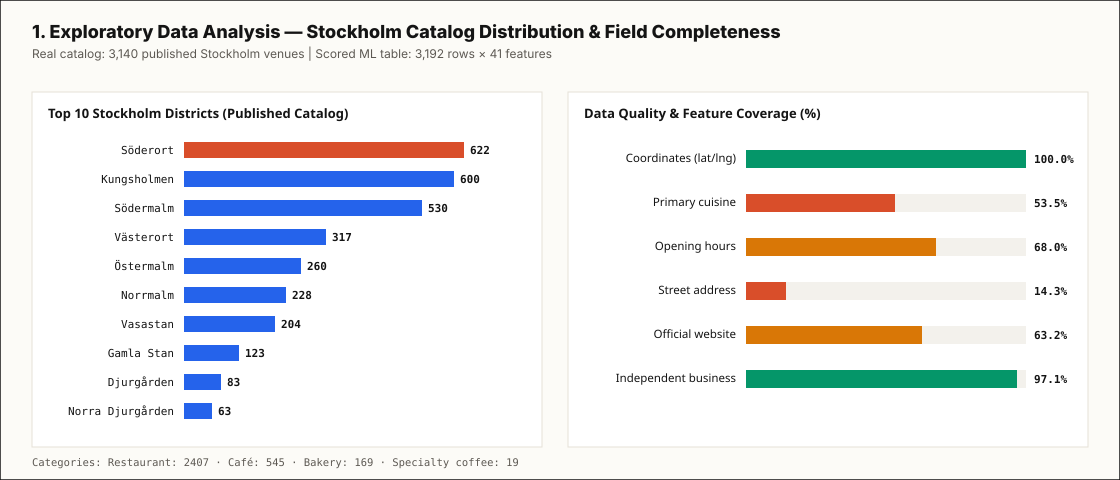

In [1]:
import json
from pathlib import Path
import pandas as pd

DATA_DIR = Path("data")
scored = pd.read_csv(DATA_DIR / "stockholm_food_places_scored.csv")
slice_data = json.loads((DATA_DIR / "places_slice.json").read_text(encoding="utf-8"))
excluded = pd.read_csv(DATA_DIR / "stockholm_food_excluded_chains.csv")
dups = pd.read_csv(DATA_DIR / "stockholm_food_duplicates.csv")

summary = slice_data["catalogSummary"]
print(f"Full published Stockholm catalog: {summary['fullCatalogTotalPlaces']:,} venues")
print(f"Cloudflare Vectorize index size : {summary['vectorIndexTotalVectors']:,} vectors (1,024-dim @cf/baai/bge-m3)")
print(f"Stratified exam slice           : {slice_data['sliceCount']} venues")
print(f"Scored ML feature table         : {scored.shape[0]:,} rows x {scored.shape[1]} engineered features")
print(f"Excluded commercial chains audit: {len(excluded)} chain rows filtered out")
print(f"Deduplication audit log         : {len(dups)} merged duplicate rows")


In [2]:
print("Top 10 primary cuisines in scored ML table:")
print(scored["primary_cuisine"].fillna("missing").value_counts().head(10).to_string())
print("\nMissingness & quality ratios:")
for col in ["missing_address", "missing_opening_hours", "missing_website", "independent_business", "underrepresented_cuisine", "is_structural_anomaly"]:
    print(f"  {col:26s}: {scored[col].mean()*100:5.1f}%")


Top 10 primary cuisines in scored ML table:
primary_cuisine
missing        1484
pizza           236
sushi           191
italian         121
coffee shop     117
burger          108
thai             89
asian            85
indian           82
japanese         56

Missingness & quality ratios:
  missing_address           :  85.7%
  missing_opening_hours     :  32.0%
  missing_website           :  74.2%
  independent_business      :  97.1%
  underrepresented_cuisine  :  29.2%
  is_structural_anomaly     :   7.0%


### Key EDA Findings
- **Strong geographic & category structure**: `Restaurant` and `Café` dominate, with Södermalm, Norrmalm, Vasastan, Östermalm, and Kungsholmen forming dense urban clusters.
- **Commercial chain & non-food gating is essential before scoring or RAG**: Without hard deterministic gates (`lib/catalog-exclusions.ts` & `motkarta/catalog_exclusions.py`), chain volume skews popularity baselines and pollutes semantic retrieval.
- **Structural anomalies (`is_structural_anomaly`)**: Isolation Forest flags venues with unusual combinations of spatial density, tag complexity, and profile completeness for human review rather than blind auto-promotion.


Structural anomalies flagged by Isolation Forest: 222 / 3192 (7.0%)
              name establishment_type primary_cuisine  spatial_density_300m  discovery_score
         Santorini         Restaurant           greek                 137.0               80
          Taco Bar         Restaurant         tex-mex                 126.0               80
           Ramblas         Restaurant         spanish                  36.0               80
       Two Indians         Restaurant          indian                  64.0               80
     Happy Rooster         Restaurant           asian                  99.0               80
  Strömmingsvagnen         Restaurant         herring                 103.0               80
Thailändska Tigern         Restaurant            thai                 120.0               80
       Kebabkungen         Restaurant           kebab                  63.0               80


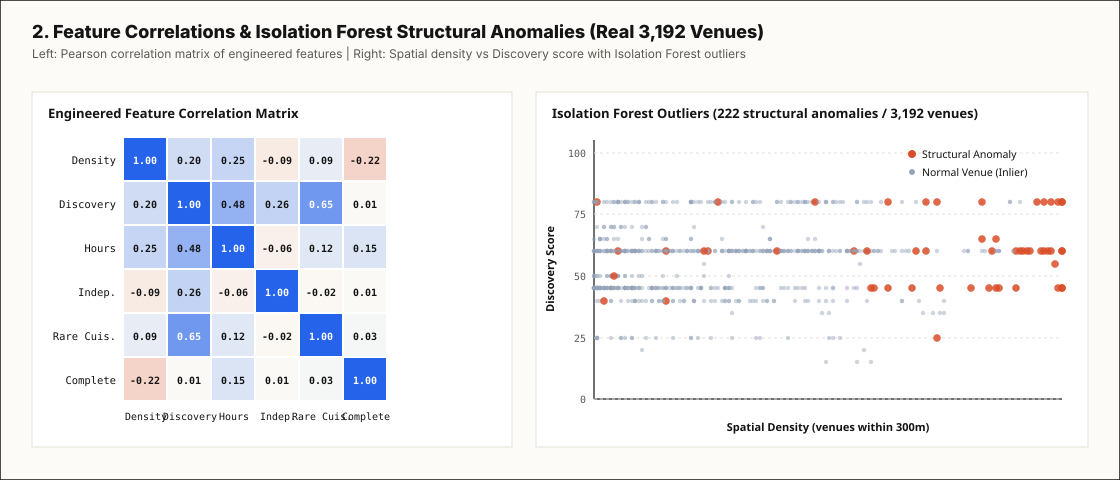

In [3]:
anomalies = scored[scored["is_structural_anomaly"]].sort_values("discovery_score", ascending=False)
print(f"Structural anomalies flagged by Isolation Forest: {len(anomalies)} / {len(scored)} ({len(anomalies)/len(scored)*100:.1f}%)")
print(anomalies[["name", "establishment_type", "primary_cuisine", "spatial_density_300m", "discovery_score"]].head(8).to_string(index=False))
